Mounted at /content/drive
🤖 Carregando o modelo: /content/drive/MyDrive/modelo_pragas_feijao_v2.keras ...
✅ Modelo carregado com sucesso!
📐 Resolução esperada pelo modelo: 150x150
📋 Ordem oficial das classes: ['mosca_branca', 'saudavel', 'sintomas']

=== SISTEMA DE DIAGNÓSTICO PLAGUEHIT ===
Selecione a foto da folha para avaliar:


Saving healthy_213.jpg to healthy_213.jpg

🔄 Processando arquivo enviado: "healthy_213.jpg"...



/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['input_layer']]
Received: inputs=Tensor(shape=(1, 150, 150, 3))
  warnings.warn(msg)


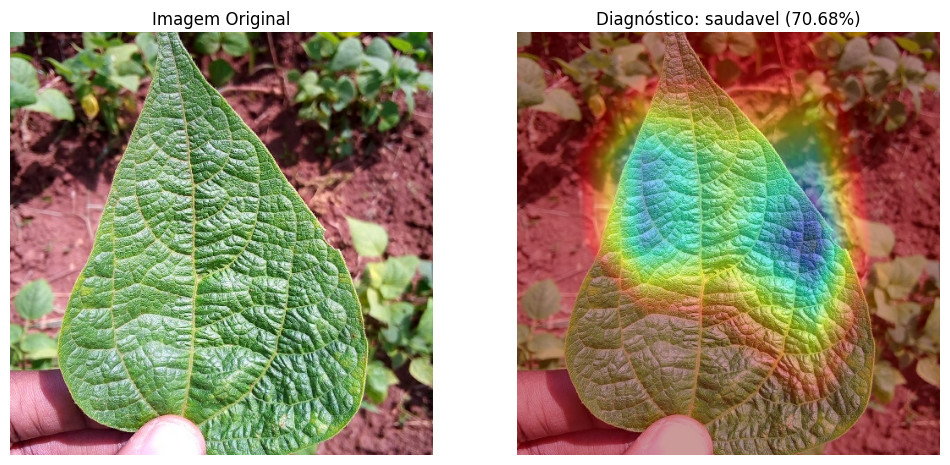

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from google.colab import drive, files
from tensorflow.keras.models import Model

# ==============================================================================
# 1. CARREGAMENTO DO MODELO E LEITURA DINÂMICA DAS DIMENSÕES
# ==============================================================================
if not os.path.exists('/content/drive/MyDrive'):
  drive.mount('/content/drive')

caminho_modelo = '/content/drive/MyDrive/modelo_pragas_feijao_v2.keras'
if not os.path.exists(caminho_modelo):
  caminho_modelo = '/content/drive/MyDrive/modelo_pragas_feijao.keras'

print(f'🤖 Carregando o modelo: {caminho_modelo} ...')
model = tf.keras.models.load_model(caminho_modelo)
print('✅ Modelo carregado com sucesso!')

# Identifica automaticamente a largura e altura esperadas pelo modelo (ex: 150x150)
TARGET_H = model.input_shape[1]
TARGET_W = model.input_shape[2]
print(f'📐 Resolução esperada pelo modelo: {TARGET_W}x{TARGET_H}')

CLASSES = ['mosca_branca', 'saudavel', 'sintomas']
print(f'📋 Ordem oficial das classes: {CLASSES}\n')


# ==============================================================================
# 2. FUNÇÃO GRAD-CAM COM SUPORTE AUTOMÁTICO A CAMADAS E RESOLUÇÃO
# ==============================================================================
def analisar_imagem_com_mapa(img_path, modelo_treinado, lista_classes):
  img_original = cv2.imread(img_path)
  if img_original is None:
    print(f'❌ Erro ao ler a imagem: {img_path}')
    return

  img_original = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)

  # Redimensiona para o tamanho exato que o modelo espera (150, 150)
  img_redimensionada = cv2.resize(img_original, (TARGET_W, TARGET_H))
  raio_x = np.expand_dims(img_redimensionada, axis=0) / 255.0

  # Localiza dinamicamente a última camada convolucional da rede
  ultima_camada_conv = None
  for layer in reversed(modelo_treinado.layers):
    if (
        'conv' in layer.name.lower()
        or isinstance(layer, tf.keras.layers.Conv2D)
        or 'Conv_1' in layer.name
    ):
      ultima_camada_conv = layer.name
      break

  if not ultima_camada_conv:
    ultima_camada_conv = 'Conv_1'

  grad_model = Model(
      inputs=[modelo_treinado.inputs],
      outputs=[
          modelo_treinado.get_layer(ultima_camada_conv).output,
          modelo_treinado.output,
      ],
  )

  with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(raio_x)
    classe_predita_idx = np.argmax(predictions[0])
    perda = predictions[0][classe_predita_idx]

  grads = tape.gradient(perda, conv_outputs)[0]
  cam = np.dot(conv_outputs[0], tf.reduce_mean(grads, axis=(0, 1)))

  # Redimensiona o mapa de calor de volta ao tamanho original da folha
  cam = cv2.resize(cam, (img_original.shape[1], img_original.shape[0]))
  cam = np.maximum(cam, 0)

  mapa_calor = (cam - cam.min()) / (cam.max() - cam.min() + 1e-10)
  mapa_calor = np.uint8(255 * mapa_calor)
  mapa_calor = cv2.applyColorMap(mapa_calor, cv2.COLORMAP_JET)

  imagem_final = cv2.addWeighted(img_original, 0.6, mapa_calor, 0.4, 0)

  nome_classe = lista_classes[classe_predita_idx]
  confianca = float(predictions[0][classe_predita_idx]) * 100

  plt.figure(figsize=(12, 6))
  plt.subplot(1, 2, 1)
  plt.title('Imagem Original')
  plt.imshow(img_original)
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.title(f'Diagnóstico: {nome_classe} ({confianca:.2f}%)')
  plt.imshow(imagem_final)
  plt.axis('off')
  plt.show()


# ==============================================================================
# 3. INTERFACE DE UPLOAD E PROCESSAMENTO
# ==============================================================================
print('=== SISTEMA DE DIAGNÓSTICO PLAGUEHIT ===')
print('Selecione a foto da folha para avaliar:')

uploaded = files.upload()

for nome_arquivo in uploaded.keys():
  print(f'\n🔄 Processando arquivo enviado: "{nome_arquivo}"...\n')
  analisar_imagem_com_mapa(nome_arquivo, model, CLASSES)

In [6]:
import os
import tensorflow as tf
from google.colab import drive

# 1. Garante que o Google Drive está montado
if not os.path.exists('/content/drive/MyDrive'):
  drive.mount('/content/drive')

# 2. Define o caminho do modelo e verifica alternativa caso não exista
caminho_modelo = '/content/drive/MyDrive/modelo_pragas_feijao_v2.keras'
if not os.path.exists(caminho_modelo):
  caminho_modelo = '/content/drive/MyDrive/modelo_pragas_feijao.keras'

# 3. Carrega e exibe o resumo do modelo
if os.path.exists(caminho_modelo):
  print(f'🤖 Carregando o modelo de: {caminho_modelo}')
  modelo = tf.keras.models.load_model(caminho_modelo)
  modelo.summary()
else:
  print('❌ Erro: O arquivo do modelo não foi encontrado no seu Google Drive. Certifique-se de que o arquivo está na pasta raiz do seu Drive.')

Mounted at /content/drive
🤖 Carregando o modelo de: /content/drive/MyDrive/modelo_pragas_feijao_v2.keras


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 150, 150,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 75, 75,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 75, 75,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 75, 75,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 75, 75,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 75, 75,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 75, 75,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 75, 75,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 75, 75,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 77, 77,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 38, 38,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 38, 38,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 38, 38,    │      2,304 │ block_1_depthwis

 Total params: 3,254,347 (12.41 MB)

 Trainable params: 331,267 (1.26 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

 Optimizer params: 662,536 (2.53 MB)

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Aponte para a pasta onde estão as suas imagens de teste/validação
# Atenção: Se o seu dataset não estiver dividido em pastas de 'treino' e 'teste', aponte para a pasta principal e usaremos o validation_split.
caminho_dataset = '/content/drive/MyDrive/dataset_feijao'

# Cria o gerador normalizando os pixels (0 a 1)
gerador = ImageDataGenerator(rescale=1./255, validation_split=0.2) # Separa 20% das imagens para teste

# Carrega as imagens de teste
dados_teste = gerador.flow_from_directory(
    caminho_dataset,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    subset='validation' # Usa apenas a parte separada para teste
)

# Avalia o modelo
perda, acuracia = modelo.evaluate(dados_teste)
print(f"\nAcurácia do modelo: {acuracia * 100:.2f}%")

Found 72 images belonging to 3 classes.
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 690ms/step - accuracy: 0.8750 - loss: 0.3358

Acurácia do modelo: 87.50%
